In [16]:
import os, time, json, random, copy, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms, datasets
import torchvision
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from PIL import Image

SEED = 42
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
BATCH_SIZE = 32
PATIENCE = 4
WEIGHT_DECAY = 1e-2
RUN_B5 = False
OUT_DIR = "outputs"
os.makedirs(OUT_DIR, exist_ok=True)

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed()
print("Device:", DEVICE, "| torch", torch.__version__, "| torchvision", torchvision.__version__)
if DEVICE == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda | torch 2.11.0+cu130 | torchvision 0.26.0+cu130
GPU: Tesla T4


1. Data subset 10 kelas + data split stratified 70/15/15

In [17]:
DATA_ROOT = "data"
parts = [datasets.OxfordIIITPet(DATA_ROOT, split=s, target_types="category", download=True)
         for s in ("trainval", "test")]
all_classes = parts[0].classes

CAT_BREEDS = ["Abyssinian", "Bengal", "Birman", "Bombay", "Persian"]
DOG_BREEDS = ["Beagle", "Boxer", "Pug", "Samoyed", "Shiba Inu"]
CLASSES = CAT_BREEDS + DOG_BREEDS
NUM_CLASSES = len(CLASSES)
missing = [c for c in CLASSES if c not in all_classes]
assert not missing, f"Nama kelas tidak ditemukan: {missing}. Tersedia: {all_classes}"

orig_to_new = {parts[0].class_to_idx[c]: i for i, c in enumerate(CLASSES)}
paths, labels = [], []
for p in parts:
    for img_path, lab in zip(p._images, p._labels):
        if lab in orig_to_new:
            paths.append(str(img_path))
            labels.append(orig_to_new[lab])
labels = np.array(labels)
print("Total citra subset:", len(paths))

idx = np.arange(len(paths))
train_idx, tmp_idx = train_test_split(idx, test_size=0.30, stratify=labels, random_state=SEED)
val_idx, test_idx = train_test_split(tmp_idx, test_size=0.50, stratify=labels[tmp_idx], random_state=SEED)
assert not (set(train_idx) & set(val_idx) or set(train_idx) & set(test_idx) or set(val_idx) & set(test_idx)), "Data leakage!"
print(f"Train {len(train_idx)} | Val {len(val_idx)} | Test {len(test_idx)}")
print(pd.DataFrame({
    "kelas": CLASSES,
    "train": np.bincount(labels[train_idx], minlength=NUM_CLASSES),
    "val": np.bincount(labels[val_idx], minlength=NUM_CLASSES),
    "test": np.bincount(labels[test_idx], minlength=NUM_CLASSES),
}).to_string(index=False))

with open(f"{OUT_DIR}/split_indices.json", "w") as f:
    json.dump({"seed": SEED, "classes": CLASSES,
               "train": [paths[i] for i in train_idx],
               "val": [paths[i] for i in val_idx],
               "test": [paths[i] for i in test_idx]}, f)

t0 = time.time()
resize256 = transforms.Resize(256)
cache = [resize256(Image.open(p).convert("RGB")) for p in paths]
print(f"Pre-load selesai dalam {time.time()-t0:.1f}s")

Total citra subset: 1981
Train 1386 | Val 297 | Test 298
     kelas  train  val  test
Abyssinian    138   30    30
    Bengal    140   30    30
    Birman    140   30    30
    Bombay    129   27    28
   Persian    140   30    30
    Beagle    140   30    30
     Boxer    139   30    30
       Pug    140   30    30
   Samoyed    140   30    30
 Shiba Inu    140   30    30
Pre-load selesai dalam 13.9s


2. Transformation

In [18]:
WEIGHTS = models.ResNet18_Weights.IMAGENET1K_V1
MEAN, STD = WEIGHTS.transforms().mean, WEIGHTS.transforms().std

train_tf_aug = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD),
])
train_tf_noaug = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD),
])
eval_tf = WEIGHTS.transforms()

class PetSubset(Dataset):
    def __init__(self, indices, tf):
        self.indices, self.tf = list(indices), tf
    def __len__(self):
        return len(self.indices)
    def __getitem__(self, i):
        j = self.indices[i]
        return self.tf(cache[j]), int(labels[j])

def seed_worker(worker_id):
    s = torch.initial_seed() % 2**32
    np.random.seed(s); random.seed(s)

def make_loader(indices, tf, shuffle):
    g = torch.Generator(); g.manual_seed(SEED)
    return DataLoader(PetSubset(indices, tf), batch_size=BATCH_SIZE, shuffle=shuffle,
                      num_workers=2, pin_memory=True, persistent_workers=True,
                      worker_init_fn=seed_worker, generator=g)

val_loader = make_loader(val_idx, eval_tf, shuffle=False)
test_loader = make_loader(test_idx, eval_tf, shuffle=False)

3. Model builder


In [19]:
def count_params(model):
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total = sum(p.numel() for p in model.parameters())
    return trainable, total

def freeze_bn_of_frozen_layers(model):
    for m in model.modules():
        if isinstance(m, nn.BatchNorm2d) and not any(p.requires_grad for p in m.parameters()):
            m.eval()

def build(cond):
    """Mengembalikan (model, param_groups). Setiap group punya 'name' dan 'lr'."""
    if cond == "B1":
        m = models.resnet18(weights=None)
        m.fc = nn.Linear(m.fc.in_features, NUM_CLASSES)
        groups = [{"name": "all", "params": list(m.parameters()), "lr": 1e-3}]
    elif cond in ("B2", "B3"):
        m = models.resnet18(weights=WEIGHTS)
        for p in m.parameters():
            p.requires_grad = False
        m.fc = nn.Linear(m.fc.in_features, NUM_CLASSES)
        if cond == "B2":
            groups = [{"name": "fc", "params": list(m.fc.parameters()), "lr": 1e-3}]
        else:
            for p in m.layer4.parameters():
                p.requires_grad = True
            groups = [{"name": "layer4", "params": list(m.layer4.parameters()), "lr": 1e-4},
                      {"name": "fc", "params": list(m.fc.parameters()), "lr": 1e-3}]
    elif cond == "B5":
        m = models.mobilenet_v3_small(weights=models.MobileNet_V3_Small_Weights.IMAGENET1K_V1)
        for p in m.parameters():
            p.requires_grad = False
        m.classifier[3] = nn.Linear(m.classifier[3].in_features, NUM_CLASSES)
        for p in m.features[-3:].parameters():
            p.requires_grad = True
        for p in m.classifier.parameters():
            p.requires_grad = True
        groups = [{"name": "features[-3:]", "params": list(m.features[-3:].parameters()), "lr": 1e-4},
                  {"name": "classifier", "params": list(m.classifier.parameters()), "lr": 1e-3}]
    else:
        raise ValueError(cond)
    return m.to(DEVICE), groups

for c in ("B1", "B2", "B3"):
    _m, _ = build(c)
    tr, tot = count_params(_m)
    print(f"{c}: trainable {tr:,} / {tot:,}")
del _m

B1: trainable 11,181,642 / 11,181,642
B2: trainable 5,130 / 11,181,642
B3: trainable 8,398,858 / 11,181,642


4. Training loop to monitor validation loss

In [20]:
criterion = nn.CrossEntropyLoss()
USE_AMP = DEVICE == "cuda"
HISTORY, SUMMARY, TEST_OUTPUTS = [], [], {}

def run_epoch(model, loader, optimizer=None, scaler=None):
    training = optimizer is not None
    model.train(training)
    if training:
        freeze_bn_of_frozen_layers(model)
    total_loss, ys, preds, probs = 0.0, [], [], []
    for x, y in loader:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        with torch.set_grad_enabled(training), torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
            out = model(x)
            loss = criterion(out, y)
        if training:
            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
        total_loss += loss.item() * x.size(0)
        p = out.float().softmax(1)
        probs.append(p.detach().cpu()); preds.append(p.argmax(1).cpu()); ys.append(y.cpu())
    ys, preds, probs = torch.cat(ys).numpy(), torch.cat(preds).numpy(), torch.cat(probs).numpy()
    return total_loss / len(ys), accuracy_score(ys, preds), ys, preds, probs

def save_logs():
    pd.DataFrame(HISTORY).to_csv(f"{OUT_DIR}/history_per_epoch.csv", index=False)
    pd.DataFrame(SUMMARY).to_csv(f"{OUT_DIR}/summary.csv", index=False)
    with open(f"{OUT_DIR}/metrics.json", "w") as f:
        json.dump({"seed": SEED, "device": torch.cuda.get_device_name(0) if USE_AMP else "cpu",
                   "summary": SUMMARY, "history": HISTORY}, f, indent=2)

def train_condition(run_name, cond, augment=True, max_epochs=15):
    set_seed()
    model, groups = build(cond)
    trainable, total = count_params(model)
    optimizer = torch.optim.AdamW(groups, weight_decay=WEIGHT_DECAY)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    train_loader = make_loader(train_idx, train_tf_aug if augment else train_tf_noaug, shuffle=True)
    lr_info = {g["name"]: g["lr"] for g in groups}
    print(f"\n=== {run_name} | trainable {trainable:,}/{total:,} | LR {lr_info} | aug={augment} ===")

    best_val_loss, best_epoch, best_state, wait = float("inf"), 0, None, 0
    t_start = time.time()
    for epoch in range(1, max_epochs + 1):
        t_ep = time.time()
        tr_loss, tr_acc, *_ = run_epoch(model, train_loader, optimizer, scaler)
        va_loss, va_acc, *_ = run_epoch(model, val_loader)
        HISTORY.append({"run": run_name, "epoch": epoch, "train_loss": tr_loss, "train_acc": tr_acc,
                        "val_loss": va_loss, "val_acc": va_acc, "epoch_time_s": time.time() - t_ep})
        print(f"ep {epoch:02d} | train {tr_loss:.4f}/{tr_acc:.3f} | val {va_loss:.4f}/{va_acc:.3f} | {time.time()-t_ep:.1f}s")
        if va_loss < best_val_loss:
            best_val_loss, best_epoch, wait = va_loss, epoch, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            wait += 1
            if wait >= PATIENCE:
                print(f"Early stopping di epoch {epoch} (best epoch {best_epoch})")
                break
    train_time = time.time() - t_start

    model.load_state_dict(best_state)
    _, best_val_acc, *_ = run_epoch(model, val_loader)
    te_loss, te_acc, te_y, te_pred, te_prob = run_epoch(model, test_loader)
    te_f1 = f1_score(te_y, te_pred, average="macro")
    best_row = [h for h in HISTORY if h["run"] == run_name and h["epoch"] == best_epoch][0]

    SUMMARY.append({
        "run": run_name, "condition": cond, "augmentation": augment,
        "trainable_params": trainable, "total_params": total,
        "lr_per_group": json.dumps(lr_info), "weight_decay": WEIGHT_DECAY, "batch_size": BATCH_SIZE,
        "epochs_run": len([h for h in HISTORY if h["run"] == run_name]),
        "best_epoch": best_epoch, "train_time_s": round(train_time, 1),
        "best_val_loss": round(best_val_loss, 4), "val_acc": round(best_val_acc, 4),
        "train_acc_at_best": round(best_row["train_acc"], 4),
        "gap_train_minus_val": round(best_row["train_acc"] - best_row["val_acc"], 4),
        "test_acc": round(te_acc, 4), "test_macro_f1": round(te_f1, 4),
    })
    TEST_OUTPUTS[run_name] = {"y": te_y, "pred": te_pred, "prob": te_prob}
    save_logs()   # simpan setelah tiap run (aman bila runtime terputus)
    print(f"→ val_acc {best_val_acc:.4f} | test_acc {te_acc:.4f} | test macro-F1 {te_f1:.4f} | {train_time:.0f}s")
    del model; torch.cuda.empty_cache()

5. Running matriks experiment B1–B4+B5 o

In [21]:
train_condition("B1_scratch", "B1", augment=True, max_epochs=25)


=== B1_scratch | trainable 11,181,642/11,181,642 | LR {'all': 0.001} | aug=True ===
ep 01 | train 2.2664/0.212 | val 2.0755/0.269 | 7.0s
ep 02 | train 1.9778/0.288 | val 2.0430/0.269 | 8.2s
ep 03 | train 1.8276/0.332 | val 1.7862/0.350 | 6.5s
ep 04 | train 1.7643/0.362 | val 1.8466/0.333 | 7.9s
ep 05 | train 1.7101/0.383 | val 1.9291/0.364 | 7.1s
ep 06 | train 1.6792/0.400 | val 2.0774/0.296 | 7.7s
ep 07 | train 1.5796/0.445 | val 1.9274/0.333 | 8.5s
Early stopping di epoch 7 (best epoch 3)
→ val_acc 0.3502 | test_acc 0.3255 | test macro-F1 0.3204 | 53s


In [22]:
train_condition("B2_feature_extraction", "B2", augment=True, max_epochs=40)


=== B2_feature_extraction | trainable 5,130/11,181,642 | LR {'fc': 0.001} | aug=True ===
ep 01 | train 1.1546/0.707 | val 0.4754/0.916 | 6.3s
ep 02 | train 0.3727/0.940 | val 0.2617/0.970 | 7.6s
ep 03 | train 0.2333/0.964 | val 0.1893/0.970 | 6.9s
ep 04 | train 0.1830/0.962 | val 0.1768/0.963 | 8.4s
ep 05 | train 0.1532/0.971 | val 0.1414/0.976 | 6.6s
ep 06 | train 0.1318/0.978 | val 0.1312/0.976 | 7.7s
ep 07 | train 0.1203/0.973 | val 0.1299/0.973 | 6.2s
ep 08 | train 0.1078/0.978 | val 0.1426/0.973 | 7.7s
ep 09 | train 0.0963/0.980 | val 0.1251/0.973 | 6.2s
ep 10 | train 0.0982/0.973 | val 0.1031/0.980 | 7.6s
ep 11 | train 0.0845/0.984 | val 0.1098/0.966 | 6.2s
ep 12 | train 0.0750/0.986 | val 0.1030/0.970 | 7.7s
ep 13 | train 0.0742/0.987 | val 0.0978/0.976 | 6.3s
ep 14 | train 0.0709/0.985 | val 0.1034/0.970 | 7.5s
ep 15 | train 0.0643/0.987 | val 0.0994/0.973 | 6.4s
ep 16 | train 0.0563/0.990 | val 0.1157/0.973 | 7.5s
ep 17 | train 0.0592/0.986 | val 0.1031/0.970 | 6.7s
Early sto

In [23]:
train_condition("B3_finetune_layer4", "B3", augment=True, max_epochs=15)


=== B3_finetune_layer4 | trainable 8,398,858/11,181,642 | LR {'layer4': 0.0001, 'fc': 0.001} | aug=True ===
ep 01 | train 0.5920/0.840 | val 0.1189/0.966 | 6.6s
ep 02 | train 0.0980/0.977 | val 0.1046/0.970 | 7.8s
ep 03 | train 0.0590/0.986 | val 0.1199/0.966 | 6.7s
ep 04 | train 0.0457/0.989 | val 0.1273/0.960 | 7.9s
ep 05 | train 0.0245/0.996 | val 0.1319/0.970 | 6.7s
ep 06 | train 0.0223/0.994 | val 0.1145/0.973 | 7.9s
Early stopping di epoch 6 (best epoch 2)
→ val_acc 0.9697 | test_acc 0.9664 | test macro-F1 0.9667 | 44s


In [24]:
train_condition("B4_B3_no_aug", "B3", augment=False, max_epochs=15)


=== B4_B3_no_aug | trainable 8,398,858/11,181,642 | LR {'layer4': 0.0001, 'fc': 0.001} | aug=False ===
ep 01 | train 0.5138/0.867 | val 0.1091/0.970 | 2.7s
ep 02 | train 0.0426/0.991 | val 0.0960/0.976 | 2.5s
ep 03 | train 0.0171/0.999 | val 0.0963/0.980 | 3.2s
ep 04 | train 0.0100/0.999 | val 0.0950/0.973 | 3.3s
ep 05 | train 0.0057/1.000 | val 0.0992/0.976 | 2.6s
ep 06 | train 0.0036/1.000 | val 0.1020/0.973 | 2.6s
ep 07 | train 0.0027/1.000 | val 0.0979/0.976 | 2.6s
ep 08 | train 0.0023/1.000 | val 0.0981/0.976 | 3.5s
Early stopping di epoch 8 (best epoch 4)
→ val_acc 0.9731 | test_acc 0.9765 | test macro-F1 0.9767 | 23s


In [25]:
if RUN_B5:
    train_condition("B5_mobilenetv3_small", "B5", augment=True, max_epochs=15)

6. Consolidation Table (C1)

In [26]:
summary_df = pd.DataFrame(SUMMARY)
cols = ["run", "trainable_params", "lr_per_group", "best_epoch", "epochs_run", "train_time_s",
        "val_acc", "train_acc_at_best", "gap_train_minus_val", "test_acc", "test_macro_f1"]
display(summary_df[cols])
print(summary_df[cols].to_markdown(index=False))

,run,trainable_params,lr_per_group,best_epoch,epochs_run,train_time_s,val_acc,train_acc_at_best,gap_train_minus_val,test_acc,test_macro_f1
0,B1_scratch,11181642,"{""all"": 0.001}",3,7,52.8,0.3502,0.3319,-0.0183,0.3255,0.3204
1,B2_feature_extraction,5130,"{""fc"": 0.001}",13,17,119.5,0.9764,0.9870,0.0106,0.9698,0.9703
2,B3_finetune_layer4,8398858,"{""layer4"": 0.0001, ""fc"": 0.001}",2,6,43.5,0.9697,0.9769,0.0072,0.9664,0.9667
3,B4_B3_no_aug,8398858,"{""layer4"": 0.0001, ""fc"": 0.001}",4,8,23.1,0.9731,0.9993,0.0262,0.9765,0.9767


| run                   |   trainable_params | lr_per_group                    |   best_epoch |   epochs_run |   train_time_s |   val_acc |   train_acc_at_best |   gap_train_minus_val |   test_acc |   test_macro_f1 |
|:----------------------|-------------------:|:--------------------------------|-------------:|-------------:|---------------:|----------:|--------------------:|----------------------:|-----------:|----------------:|
| B1_scratch            |           11181642 | {"all": 0.001}                  |            3 |            7 |           52.8 |    0.3502 |              0.3319 |               -0.0183 |     0.3255 |          0.3204 |
| B2_feature_extraction |               5130 | {"fc": 0.001}                   |           13 |           17 |          119.5 |    0.9764 |              0.987  |                0.0106 |     0.9698 |          0.9703 |
| B3_finetune_layer4    |            8398858 | {"layer4": 0.0001, "fc": 0.001} |            2 |            6 |           43.5 |    0

7. Kurva training vs validation loss (B1, B2, B3) dan kontrol augmentasi (B4)

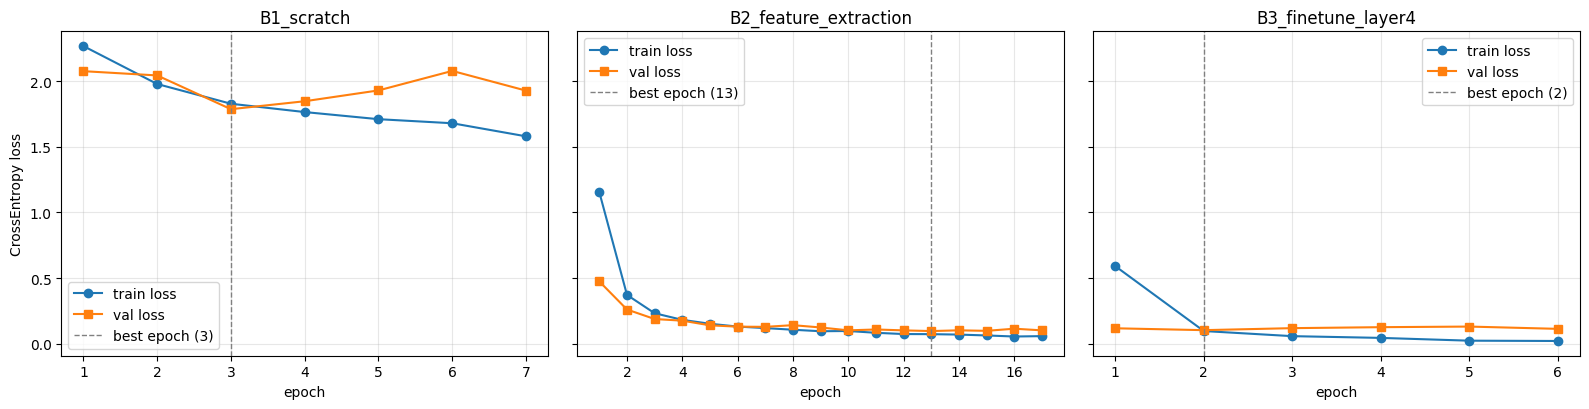

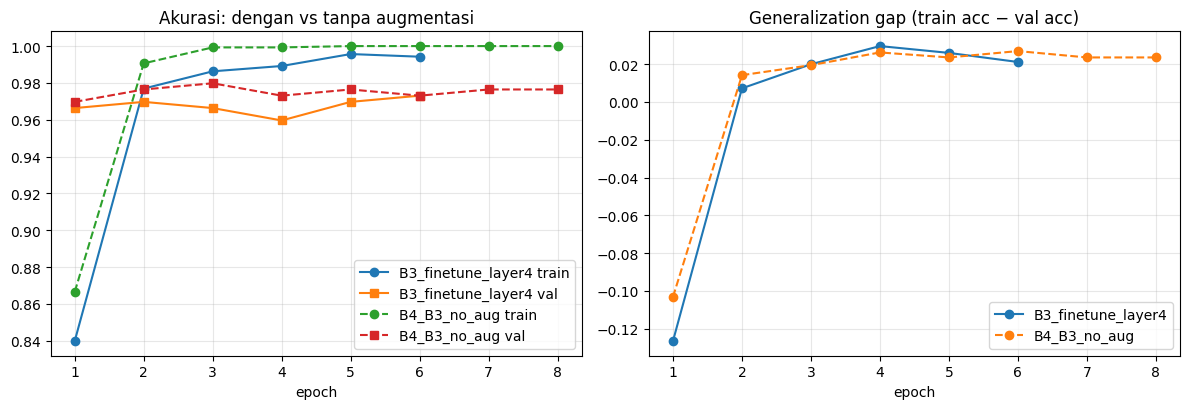

In [27]:
hist_df = pd.DataFrame(HISTORY)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), sharey=True)
for ax, run in zip(axes, ["B1_scratch", "B2_feature_extraction", "B3_finetune_layer4"]):
    h = hist_df[hist_df.run == run]
    ax.plot(h.epoch, h.train_loss, "o-", label="train loss")
    ax.plot(h.epoch, h.val_loss, "s-", label="val loss")
    best = summary_df.loc[summary_df.run == run, "best_epoch"].item()
    ax.axvline(best, ls="--", c="gray", lw=1, label=f"best epoch ({best})")
    ax.set_title(run); ax.set_xlabel("epoch"); ax.grid(alpha=.3); ax.legend()
axes[0].set_ylabel("CrossEntropy loss")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/loss_curves_B1_B2_B3.png", dpi=150); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for run, ls in [("B3_finetune_layer4", "-"), ("B4_B3_no_aug", "--")]:
    h = hist_df[hist_df.run == run]
    axes[0].plot(h.epoch, h.train_acc, ls, marker="o", label=f"{run} train")
    axes[0].plot(h.epoch, h.val_acc, ls, marker="s", label=f"{run} val")
    axes[1].plot(h.epoch, h.train_acc - h.val_acc, ls, marker="o", label=run)
axes[0].set_title("Akurasi: dengan vs tanpa augmentasi"); axes[0].set_xlabel("epoch"); axes[0].legend(); axes[0].grid(alpha=.3)
axes[1].set_title("Generalization gap (train acc − val acc)"); axes[1].set_xlabel("epoch"); axes[1].legend(); axes[1].grid(alpha=.3)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/B4_augmentation_control.png", dpi=150); plt.show()

8. Failure analysis C3


Model terbaik (berdasarkan val acc): B2_feature_extraction


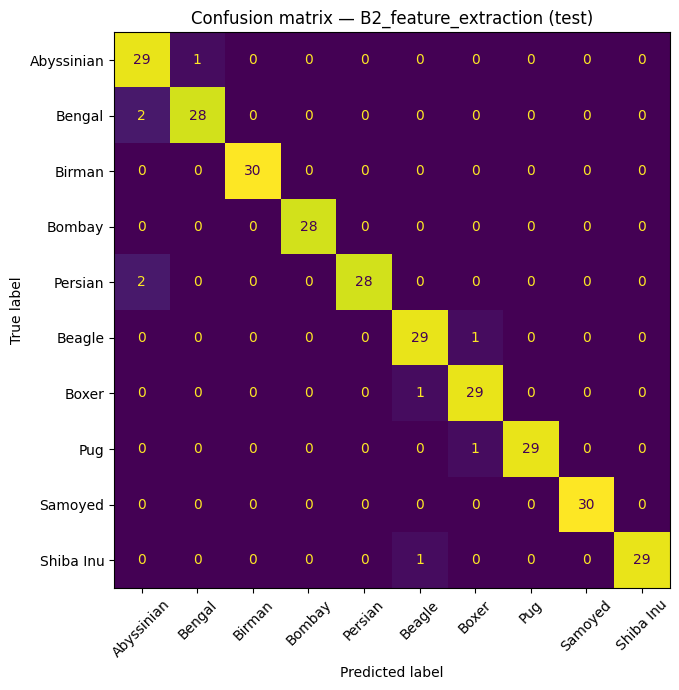

Jumlah misklasifikasi di test: 9 / 298


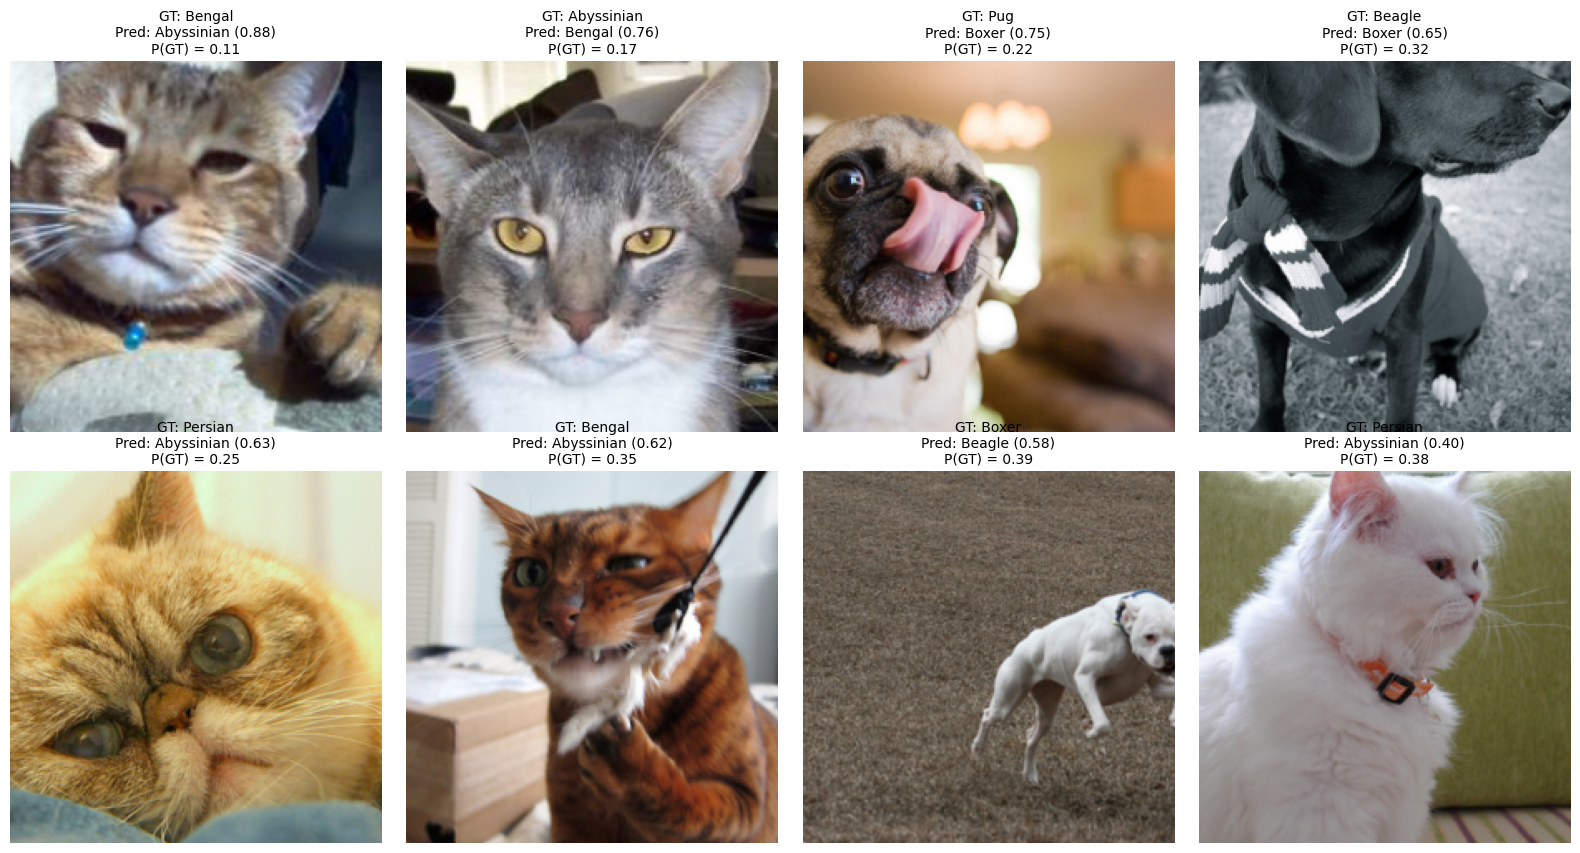

,file,ground_truth,prediction,confidence,prob_ground_truth
0,Bengal_143.jpg,Bengal,Abyssinian,0.8782,0.1127
1,Abyssinian_221.jpg,Abyssinian,Bengal,0.7612,0.1689
2,pug_6.jpg,Pug,Boxer,0.7550,0.2151
3,beagle_198.jpg,Beagle,Boxer,0.6461,0.3208
4,Persian_25.jpg,Persian,Abyssinian,0.6270,0.2470
5,Bengal_84.jpg,Bengal,Abyssinian,0.6163,0.3513
6,boxer_18.jpg,Boxer,Beagle,0.5824,0.3940
7,Persian_77.jpg,Persian,Abyssinian,0.4037,0.3827


In [28]:
best_run = summary_df.sort_values("val_acc", ascending=False).iloc[0]["run"]
print("Model terbaik (berdasarkan val acc):", best_run)
out = TEST_OUTPUTS[best_run]

cm = confusion_matrix(out["y"], out["pred"], labels=range(NUM_CLASSES))
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(ax=ax, xticks_rotation=45, colorbar=False)
ax.set_title(f"Confusion matrix — {best_run} (test)")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/confusion_matrix_best.png", dpi=150); plt.show()

wrong = np.where(out["pred"] != out["y"])[0]
conf = out["prob"][wrong, out["pred"][wrong]]
wrong = wrong[np.argsort(-conf)][:8]
print(f"Jumlah misklasifikasi di test: {(out['pred'] != out['y']).sum()} / {len(out['y'])}")

rows = []
n = len(wrong)
if n > 0:
    fig, axes = plt.subplots(2, 4, figsize=(16, 8.5))
    for ax in axes.ravel():
        ax.axis("off")
    for ax, k in zip(axes.ravel(), wrong):
        j = test_idx[k]
        img = transforms.CenterCrop(224)(cache[j])
        gt, pr, pc = CLASSES[out["y"][k]], CLASSES[out["pred"][k]], out["prob"][k, out["pred"][k]]
        p_gt = out["prob"][k, out["y"][k]]
        ax.imshow(img)
        ax.set_title(f"GT: {gt}\nPred: {pr} ({pc:.2f})\nP(GT) = {p_gt:.2f}", fontsize=10)
        rows.append({"file": os.path.basename(paths[j]), "ground_truth": gt, "prediction": pr,
                     "confidence": round(float(pc), 4), "prob_ground_truth": round(float(p_gt), 4)})
    plt.tight_layout(); plt.savefig(f"{OUT_DIR}/failure_cases.png", dpi=150); plt.show()
fail_df = pd.DataFrame(rows)
fail_df.to_csv(f"{OUT_DIR}/failure_cases.csv", index=False)
display(fail_df)

9. environment & requirements

In [29]:
import sklearn
env = {"python": platform.python_version(), "torch": torch.__version__, "torchvision": torchvision.__version__,
       "numpy": np.__version__, "pandas": pd.__version__, "scikit-learn": sklearn.__version__,
       "seed": SEED, "device": torch.cuda.get_device_name(0) if USE_AMP else "cpu"}
print(json.dumps(env, indent=2))
with open(f"{OUT_DIR}/environment.json", "w") as f:
    json.dump(env, f, indent=2)
with open("requirements.txt", "w") as f:
    f.write(f"torch=={torch.__version__.split('+')[0]}\ntorchvision=={torchvision.__version__.split('+')[0]}\n"
            f"numpy=={np.__version__}\npandas=={pd.__version__}\nscikit-learn=={sklearn.__version__}\n"
            f"matplotlib\ntabulate\nPillow\n")
print(open("requirements.txt").read())

{
  "python": "3.13.15",
  "torch": "2.11.0+cu130",
  "torchvision": "0.26.0+cu130",
  "numpy": "2.1.3",
  "pandas": "2.2.3",
  "scikit-learn": "1.6.1",
  "seed": 42,
  "device": "Tesla T4"
}
torch==2.11.0
torchvision==0.26.0
numpy==2.1.3
pandas==2.2.3
scikit-learn==1.6.1
matplotlib
tabulate
Pillow



10. log CSV/JSON + gambar

In [30]:
import shutil
shutil.copy("requirements.txt", f"{OUT_DIR}/requirements.txt")
shutil.make_archive("transferLearning_outputs", "zip", OUT_DIR)
try:
    from google.colab import files
    files.download("transferLearning_outputs.zip")
except Exception:
    print("file: transferLearning_outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>